Iteration 11: Pheromone re-initialized
Iteration 21: Pheromone re-initialized
Iteration 31: Pheromone re-initialized
Iteration 41: Pheromone re-initialized
Iteration 51: Pheromone re-initialized
Iteration 61: Pheromone re-initialized
Iteration 71: Pheromone re-initialized
Iteration 81: Pheromone re-initialized
Iteration 91: Pheromone re-initialized
Iteration 101: Pheromone re-initialized
Iteration 111: Pheromone re-initialized
Iteration 121: Pheromone re-initialized
Iteration 131: Pheromone re-initialized
Iteration 141: Pheromone re-initialized
Iteration 151: Pheromone re-initialized
Iteration 161: Pheromone re-initialized
Iteration 171: Pheromone re-initialized
Iteration 181: Pheromone re-initialized
Iteration 191: Pheromone re-initialized

MACO-LR: TRAVELLING SALESMAN PROBLEM
------------------------------------
Number of cities: 20
Number of ants: 40
Number of iterations: 200
Best tour: 7 -> 9 -> 6 -> 13 -> 11 -> 2 -> 19 -> 14 -> 15 -> 5 -> 3 -> 4 -> 17 -> 0 -> 16 -> 12 -> 1 -> 8 ->

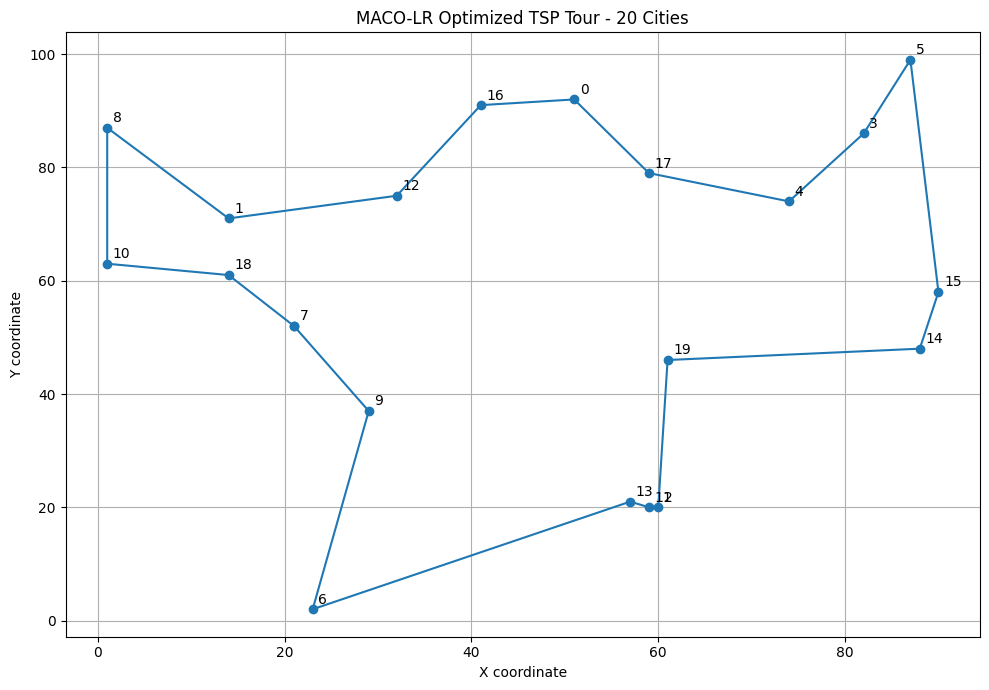

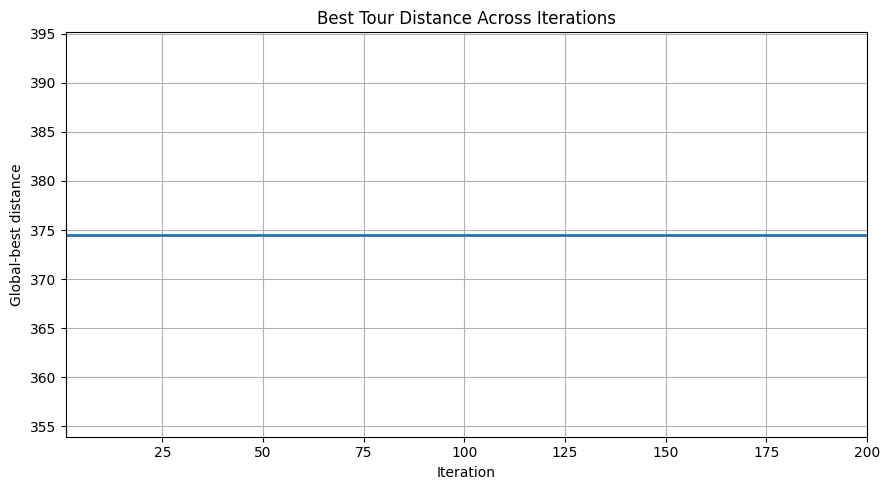

In [9]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

NUM_CITIES = 20
NUM_ANTS = 40
MAX_ITERATIONS = 200
ALPHA = 1.0
BETA = 2.0
EVAPORATION = 0.05
Q = 1.0
RP = 10
NUM_REINITIALIZE = 5

CITIES = np.random.randint(0, 100, size=(NUM_CITIES, 2))

DISTANCE = np.linalg.norm(
    CITIES[:, None, :] - CITIES[None, :, :], axis=2
)
np.fill_diagonal(DISTANCE, 0)

nearest = np.min(
    np.where(np.eye(NUM_CITIES, dtype=bool), np.inf, DISTANCE),
    axis=1
)
INITIAL_PHEROMONE = 1.0 / (NUM_CITIES * np.sum(nearest))


def tour_length(tour):
    return sum(
        DISTANCE[tour[i], tour[(i + 1) % NUM_CITIES]]
        for i in range(NUM_CITIES)
    )


def construct_tour(pheromone):
    start = np.random.randint(NUM_CITIES)
    tour = [start]
    unvisited = set(range(NUM_CITIES))
    unvisited.remove(start)

    while unvisited:
        current = tour[-1]
        candidates = list(unvisited)

        weights = np.array([
            pheromone[current, city] ** ALPHA
            * (1.0 / max(DISTANCE[current, city], 1e-10)) ** BETA
            for city in candidates
        ])

        total = weights.sum()

        if total == 0 or not np.isfinite(total):
            next_city = np.random.choice(candidates)
        else:
            probabilities = weights / total
            next_city = np.random.choice(
                candidates, p=probabilities
            )

        tour.append(next_city)
        unvisited.remove(next_city)

    return tour


def two_opt(tour):
    best = tour[:]
    best_length = tour_length(best)
    improved = True

    while improved:
        improved = False

        for i in range(NUM_CITIES - 1):
            for j in range(i + 2, NUM_CITIES):
                if i == 0 and j == NUM_CITIES - 1:
                    continue

                candidate = (
                    best[:i + 1]
                    + best[i + 1:j + 1][::-1]
                    + best[j + 1:]
                )

                candidate_length = tour_length(candidate)

                if candidate_length < best_length - 1e-9:
                    best = candidate
                    best_length = candidate_length
                    improved = True
                    break

            if improved:
                break

    return best


def maco_lr():
    pheromone = np.full(
        (NUM_CITIES, NUM_CITIES), INITIAL_PHEROMONE
    )
    np.fill_diagonal(pheromone, 0)

    global_best = None
    global_best_length = float("inf")
    unchanged = 0
    history = []

    for iteration in range(MAX_ITERATIONS):
        previous_best = global_best_length
        iteration_best = None
        iteration_best_length = float("inf")

        for _ in range(NUM_ANTS):
            tour = construct_tour(pheromone)
            length = tour_length(tour)

            if length < iteration_best_length:
                iteration_best = tour[:]
                iteration_best_length = length

        # Improve the iteration's best route using 2-Opt
        iteration_best = two_opt(iteration_best)
        iteration_best_length = tour_length(iteration_best)

        # Update the global leader only when a better route is found
        if iteration_best_length < global_best_length - 1e-9:
            global_best = iteration_best[:]
            global_best_length = iteration_best_length

        # Evaporate pheromone
        pheromone *= (1.0 - EVAPORATION)

        # Deposit pheromone using the global-best leader
        deposit = Q / global_best_length

        for i in range(NUM_CITIES):
            a = global_best[i]
            b = global_best[(i + 1) % NUM_CITIES]
            pheromone[a, b] += deposit
            pheromone[b, a] += deposit

        np.fill_diagonal(pheromone, 0)

        # Detect stagnation
        if global_best_length < previous_best - 1e-9:
            unchanged = 0
        else:
            unchanged += 1

        # Re-initialize selected pheromone trails
        if unchanged >= RP:
            edges = [
                (i, j)
                for i in range(NUM_CITIES)
                for j in range(i + 1, NUM_CITIES)
            ]

            selected = np.random.choice(
                len(edges),
                size=min(NUM_REINITIALIZE, len(edges)),
                replace=False
            )

            for index in selected:
                i, j = edges[index]
                pheromone[i, j] = INITIAL_PHEROMONE
                pheromone[j, i] = INITIAL_PHEROMONE

            unchanged = 0
            print(
                f"Iteration {iteration + 1}: "
                "Pheromone re-initialized"
            )

        history.append(global_best_length)

    return global_best, global_best_length, history


def display_results(tour, length, history):
    closed_tour = tour + [tour[0]]
    points = CITIES[closed_tour]

    print("\nMACO-LR: TRAVELLING SALESMAN PROBLEM")
    print("------------------------------------")
    print("Number of cities:", NUM_CITIES)
    print("Number of ants:", NUM_ANTS)
    print("Number of iterations:", MAX_ITERATIONS)
    print("Best tour:", " -> ".join(map(str, closed_tour)))
    print("Best tour distance:", round(length, 3))

    # Graph 1: Optimized TSP tour
    plt.figure(figsize=(10, 7))
    plt.plot(
        points[:, 0], points[:, 1],
        "o-", linewidth=1.5, markersize=6
    )

    for i, (x, y) in enumerate(CITIES):
        plt.annotate(
            str(i), (x, y),
            xytext=(4, 4), textcoords="offset points"
        )

    plt.title("MACO-LR Optimized TSP Tour - 20 Cities")
    plt.xlabel("X coordinate")
    plt.ylabel("Y coordinate")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Graph 2: Global-best distance convergence
    plt.figure(figsize=(9, 5))
    plt.plot(
        range(1, len(history) + 1),
        history,
        linewidth=2
    )

    plt.title("Best Tour Distance Across Iterations")
    plt.xlabel("Iteration")
    plt.ylabel("Global-best distance")
    plt.xlim(1, MAX_ITERATIONS)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    best_tour, best_distance, history = maco_lr()
    display_results(best_tour, best_distance, history)
